# Exercício 8 — Melhores filmes: ação ou romance?

**Enunciado:** O conjunto `movies_sample` contém uma amostra aleatória de 68 filmes da base `movies` (pacote `ggplot2movies`): 32 de ação e 36 de romance. As variáveis `title`, `year`, `rating` e `genre` indicam o título, o ano, a nota no IMDb (até 10) e o gênero (`Action` ou `Romance`).

Sejam $\mu_A$ e $\mu_R$ as médias das notas dos filmes de ação e de romance na base original. Queremos investigar se essas médias diferem. Suponha que as observações de filmes distintos sejam independentes.

- (a) O que representa cada linha? Calcule tamanho da amostra, média e desvio padrão das notas de cada gênero. Construa boxplots e histogramas por grupo e discuta assimetria e valores extremos. A sobreposição dos boxplots, por si só, permite decidir se as médias populacionais são iguais?
- (b) Formule $H_0$ e $H_1$, proponha uma estatística de teste e encontre um IC de 95% para o parâmetro testado. Calcule o valor observado da estatística e o p-valor.
- (c) Apresente as decisões para $\alpha = 0.05$ e $\alpha = 0.001$. Não rejeitar $H_0$ a 0.1% seria evidência de que as médias são iguais? Isso seria incompatível com um IC de 95% que não contivesse zero?
- (d) Os dados permitem concluir que o gênero de um filme causa uma mudança em sua nota?

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import erf, sqrt

def Phi(x):
    # CDF da N(0,1)
    return 0.5 * (1 + erf(x / sqrt(2)))

filmes = pd.read_csv('../dados_lista3/movies_sample.csv')
filmes.head()

,title,year,rating,genre
0,Underworld,1985,3.1,Action
1,Love Affair,1932,6.3,Romance
2,Junglee,1961,6.8,Romance
3,"Eversmile, New Jersey",1989,5.0,Romance
4,Search and Destroy,1979,4.0,Action


## Item (a)

Cada linha da base é **um filme**: é a unidade da amostra.

In [9]:
acao = filmes[filmes['genre'] == 'Action']['rating']
romance = filmes[filmes['genre'] == 'Romance']['rating']

print(f"Acao:    n = {len(acao)}, media = {acao.mean():.3f}, dp = {acao.std():.3f}")
print(f"Romance: n = {len(romance)}, media = {romance.mean():.3f}, dp = {romance.std():.3f}")

Acao:    n = 32, media = 5.275, dp = 1.361
Romance: n = 36, media = 6.322, dp = 1.610


Obs: o `.std()` do pandas já usa $n - 1$ no denominador, ou seja, é o desvio padrão amostral $S$.

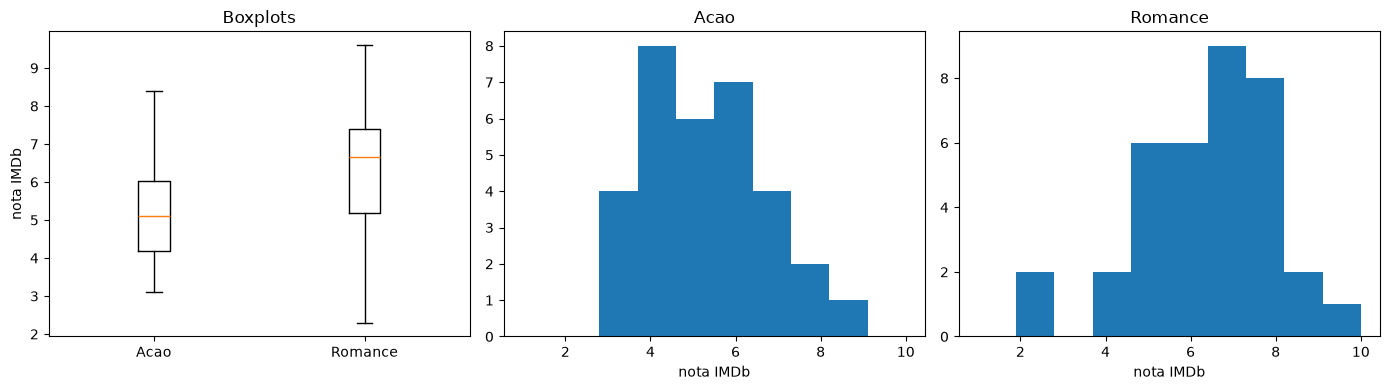

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

ax[0].boxplot([acao, romance])
ax[0].set_xticks([1, 2], ['Acao', 'Romance'])
ax[0].set_ylabel('nota IMDb')
ax[0].set_title('Boxplots')

ax[1].hist(acao, bins=10, range=(1, 10))
ax[1].set_title('Acao')
ax[1].set_xlabel('nota IMDb')

ax[2].hist(romance, bins=10, range=(1, 10))
ax[2].set_title('Romance')
ax[2].set_xlabel('nota IMDb')

plt.tight_layout()
plt.show()

**Discussão:**

Ação tem média 5.28 (dp 1.36) e romance 6.32 (dp 1.61). As notas de ação são um pouco assimétricas à direita (mediana 5.1 < média), e as de romance assimétricas à esquerda (mediana 6.65 > média), com cauda puxada por alguns filmes de nota baixa. Nenhum dos boxplots mostra valores extremos pelo critério de 1.5 IQR.

Os boxplots se sobrepõem bastante, mas isso não decide nada sobre as médias: eles mostram a variação das notas de **filmes individuais** ($S \approx 1.4$–$1.6$), enquanto a incerteza sobre a **média** é o erro padrão $S/\sqrt{n} \approx 0.24$–$0.27$, bem menor. Para comparar $\mu_A$ e $\mu_R$ preciso de um teste, feito no item (b).

## Item (b)

Parâmetro: $\delta = \mu_R - \mu_A$.
$$H_0: \delta = 0 \quad \text{versus} \quad H_1: \delta \neq 0.$$

Estimador: $\hat\delta = \overline{R} - \overline{A}$. Como as amostras são independentes,
$$\text{se}(\hat\delta) = \sqrt{\frac{\sigma_R^2}{n_R} + \frac{\sigma_A^2}{n_A}}, \qquad \widehat{\text{se}} = \sqrt{\frac{S_R^2}{n_R} + \frac{S_A^2}{n_A}} \quad \text{(plug-in)}.$$

Estatística de Wald: $W = \hat\delta / \widehat{\text{se}} \approx N(0,1)$ sob $H_0$ (TCL). Rejeitamos $H_0$ se $|W| > z_{\alpha/2}$; p-valor $= 2\Phi(-|w|)$.

IC de 95% para $\delta$: $\hat\delta \pm 1.96\,\widehat{\text{se}}$.

In [11]:
delta_hat = romance.mean() - acao.mean()
se_hat = np.sqrt(romance.var() / len(romance) + acao.var() / len(acao))

W = delta_hat / se_hat
p_valor = 2 * Phi(-abs(W))

ic_inf = delta_hat - 1.96 * se_hat
ic_sup = delta_hat + 1.96 * se_hat

print(f"delta_hat = {delta_hat:.3f}")
print(f"se_hat    = {se_hat:.3f}")
print(f"W         = {W:.3f}")
print(f"p-valor   = {p_valor:.4f}")
print(f"IC 95%    = ({ic_inf:.3f}, {ic_sup:.3f})")

delta_hat = 1.047
se_hat    = 0.360
W         = 2.906
p-valor   = 0.0037
IC 95%    = (0.341, 1.754)


**Resultado:** $\hat\delta \approx 1.05$, $\widehat{\text{se}} \approx 0.36$, $w \approx 2.91$ e p-valor $\approx 0.0037$. O IC de 95% para $\delta = \mu_R - \mu_A$ é $(0.34,\ 1.75)$: as notas de romance parecem ser, em média, entre 0.3 e 1.8 ponto maiores que as de ação.

## Item (c)

Decisão: rejeitamos $H_0$ quando o p-valor é menor que $\alpha$ (equivalente a $|W| > z_{\alpha/2}$).

In [12]:
for alpha in [0.05, 0.001]:
    decisao = "rejeita H0" if p_valor < alpha else "nao rejeita H0"
    print(f"alpha = {alpha}: p-valor = {p_valor:.4f} -> {decisao}")

alpha = 0.05: p-valor = 0.0037 -> rejeita H0
alpha = 0.001: p-valor = 0.0037 -> nao rejeita H0


Para comparar com o nível 0.1%, o IC correspondente é o de 99.9% ($z_{0.0005} \approx 3.29$):

In [13]:
z999 = 3.29
print(f"IC 99.9% = ({delta_hat - z999 * se_hat:.3f}, {delta_hat + z999 * se_hat:.3f})")

IC 99.9% = (-0.138, 2.233)


**Discussão:**

A 5% rejeito $H_0$ ($p \approx 0.004$), mas a 0.1% não rejeito.

Não rejeitar $H_0$ a 0.1% **não** é evidência de que $\mu_A = \mu_R$. Só quer dizer que, com esse nível tão exigente, os dados não bastam para descartar $\delta = 0$. Ausência de rejeição não é prova de igualdade: o IC de 99.9% vai de $-0.14$ a $2.23$, ou seja, ainda é compatível com diferenças grandes a favor de romance.

Também não há incompatibilidade com o IC de 95% não conter zero. O IC de $1-\alpha$ corresponde ao teste de nível $\alpha$: o IC de 95%, $(0.34,\ 1.75)$, não contém 0, o que bate com rejeitar a 5%. O IC de 99.9% é mais largo e contém 0, o que bate com não rejeitar a 0.1%. São perguntas com exigências diferentes, e as duas respostas são coerentes.

## Item (d)

**Discussão:**

Não. Os dados são **observacionais**: ninguém sorteou o gênero de cada filme, então o teste mostra que as notas médias dos dois grupos **diferem**, não que o gênero **causa** a diferença. Outras variáveis podem estar por trás. Por exemplo, na amostra os filmes de romance são em média mais antigos (ano médio ≈ 1979, contra ≈ 1988 em ação, com romances desde 1917). Filmes antigos que ainda estão no IMDb tendem a ser os que "sobreviveram" por serem bons, o que pode inflar a nota de romance. Orçamento, público-alvo e quem vota no IMDb são outros fatores possíveis. Para falar em causa, precisaria de um experimento aleatorizado, o que aqui não faz sentido, ou pelo menos de controlar esses fatores.